# Практика по PyTorch

Аппроксимация $f(x, y) = \sin(x + 2y)\exp(-(2x + y)^2)$ на $[-10; 10]^2$.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(2)

### Данные

In [2]:
def f(X):
    x, y = X[:, 0], X[:, 1]
    return (torch.sin(x + 2 * y) * torch.exp(-(2 * x + y) ** 2)).reshape(-1, 1)

X = torch.rand(20000, 2) * 20 - 10
z = f(X)

indices = torch.randperm(len(X))
train_idx = indices[:14000]
test_idx = indices[14000:17000]
val_idx = indices[17000:]

X_train, z_train = X[train_idx], z[train_idx]
X_test, z_test = X[test_idx], z[test_idx]
X_val, z_val = X[val_idx], z[val_idx]

train_loader = DataLoader(
    TensorDataset(X_train, z_train), batch_size=256, shuffle=True
)
print(f"Train: {len(X_train)}, test: {len(X_test)}, val: {len(X_val)}")

Train: 14000, test: 3000, val: 3000


### Модель и обучение

In [3]:
model = nn.Sequential(
    nn.Linear(2, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [4]:
train_losses, val_losses = [], []
best_val_loss = float('inf')

for epoch in range(1, 501):
    model.train()
    train_loss = 0
    for X_batch, z_batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(X_batch), z_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(X_batch)

    model.eval()
    with torch.no_grad():
        val_loss = criterion(model(X_val), z_val).item()

    train_losses.append(train_loss / len(X_train))
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}

    if epoch % 100 == 0:
        print(f"Эпоха {epoch}: train MSE = {train_losses[-1]:.6f}, val MSE = {val_loss:.6f}")

model.load_state_dict(best_weights)
print(f"Лучший val MSE: {best_val_loss:.6f}")

Эпоха 100: train MSE = 0.005914, val MSE = 0.006530
Эпоха 200: train MSE = 0.000148, val MSE = 0.000113
Эпоха 300: train MSE = 0.000061, val MSE = 0.000076
Эпоха 400: train MSE = 0.000039, val MSE = 0.000023
Эпоха 500: train MSE = 0.000039, val MSE = 0.000048
Лучший val MSE: 0.000020


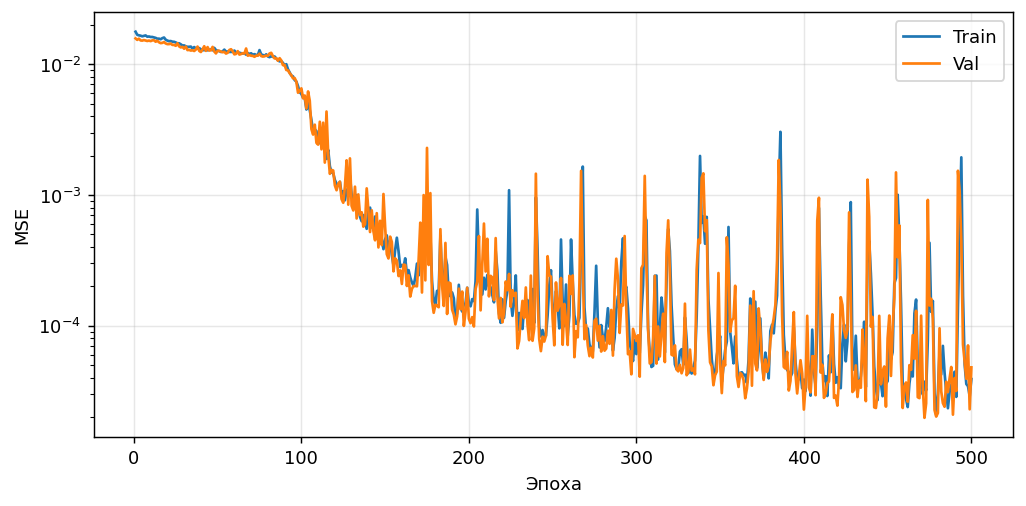

In [5]:
plt.figure(figsize=(8, 4))
plt.semilogy(range(1, 501), train_losses, label='Train')
plt.semilogy(range(1, 501), val_losses, label='Val')
plt.xlabel('Эпоха')
plt.ylabel('MSE')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### MSE на test и сравнение функций

In [6]:
model.eval()
with torch.no_grad():
    z_pred = model(X_test)
    test_mse = criterion(z_pred, z_test).item()

print(f"MSE на test: {test_mse:.8f}")

MSE на test: 0.00002640


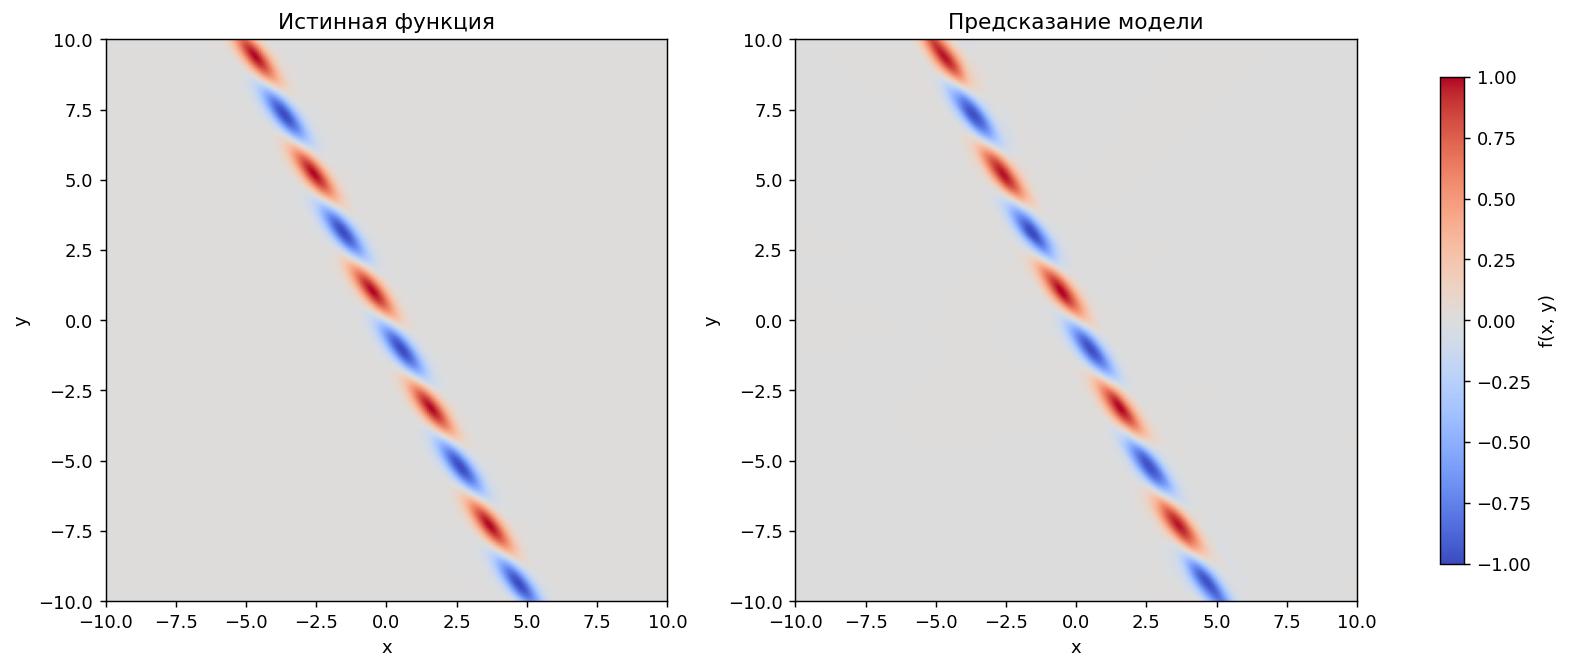

In [7]:
axis = torch.linspace(-10, 10, 301)
xx, yy = torch.meshgrid(axis, axis, indexing='xy')
X_grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)

with torch.no_grad():
    z_true = f(X_grid).reshape(xx.shape).numpy()
    z_model = model(X_grid).reshape(xx.shape).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, values, title in zip(
    axes, [z_true, z_model], ['Истинная функция', 'Предсказание модели']
):
    image = ax.imshow(
        values, extent=[-10, 10, -10, 10], origin='lower',
        cmap='coolwarm', vmin=-1, vmax=1
    )
    ax.set_title(title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

fig.colorbar(image, ax=axes, label='f(x, y)', shrink=0.85)
plt.show()

На графике слева показана истинная функция, справа — предсказание модели. Почти одинаковые формы и цвета подтверждают хорошее приближение. При этом MSE характеризует среднюю ошибку: в отдельных точках она может быть больше.